# 02 — Approcci senza apprendimento profondo: baseline, stimatori classici, grafi di visibilità

**Compito.** Stimare l'esponente di Hurst $H$ da una singola traiettoria di fBm di lunghezza $N$.

**Approcci di questo notebook**

| # | Approccio | Cosa impara dal training set |
|---|---|---|
| 0 | Baseline banale: predice sempre la media di $H$ del train | 1 numero |
| 1a | DFA (Detrended Fluctuation Analysis) | niente |
| 1b | R/S (Rescaled Range, Hurst) | niente |
| 2a | NVG del fBm, esponente $\gamma$ del grado → $H=(3-\gamma)/2$ (Lacasa et al. 2009) | niente |
| 2b | NVG del fGn, $H=(5-\gamma)/2$ | niente |
| 1a-cal, 1b-cal, 2-cal | gli stessi stimatori **ricalibrati** con una retta $H = a + b\,\hat H$ fittata sul train | 2 numeri |

Le versioni ricalibrate servono come termine di paragone onesto per il modello ibrido (D-12): se l'ibrido
batte la DFA grezza ma non la DFA ricalibrata, ha solo imparato a correggere un bias.

Ogni altro approccio del progetto dovrà battere l'approccio 0.

**Contenuto:** 1. Configurazione e dati · 2. Calcolo delle quantità fisiche · 3. Approccio 0 ·
4. Approccio 1 · 5. Approccio 2 · 6. Confronto · 7. Robustezza rispetto a $N$ · 8. Salvataggio · 9. Riepilogo

In [1]:
# --- Setup: su Colab clona il repository; ovunque installa ciò che manca ---
import os, sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Arminas00/stochastic-ml.git"
if IN_COLAB:
    repo = "/content/stochastic-ml"
    if os.path.exists(repo):
        subprocess.run(["git", "-C", repo, "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, repo], check=True)
    os.chdir(repo)

needed = ["numpy", "scipy", "pandas", "matplotlib", "sklearn", "ts2vg"]
missing = [m for m in needed if importlib.util.find_spec(m) is None]
if missing:
    print("Installo:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, os.getcwd())
print("Cartella di lavoro:", os.getcwd(), "| Colab:", IN_COLAB)

Cartella di lavoro: C:\Users\user\Downloads\AI_Project\stochastic-ml | Colab: False


## 1. Configurazione e dati

Il dataset è quello del notebook 01 (stessi `MODE` e `SEED`): se non è nella cartella `data/` viene
rigenerato identico dai seed.

In [2]:
MODE = "quick"          # deve coincidere con il notebook 01
SEED = 2026
DATA_DIR = "data"
FIG_DIR = "figures"
N_BOOT = 1000           # ricampionamenti bootstrap per gli intervalli di confidenza

In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sp_utils as u

u.set_seed(SEED)
Path(FIG_DIR).mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def savefig(name):
    plt.savefig(f"{FIG_DIR}/02_{name}.png", bbox_inches="tight", dpi=150)

CFG = u.MODES[MODE]
ds = u.load_or_make_fbm_dataset(MODE, SEED, DATA_DIR)
H = {s: d["H"].astype(np.float64) for s, d in ds.items()}
print("Split:", {s: d["X"].shape for s, d in ds.items()})

Split: {'train': (4000, 512), 'val': (1000, 512), 'test': (2000, 512), 'test_N128': (500, 128), 'test_N256': (500, 256), 'test_N1024': (500, 1024), 'test_N2048': (500, 2048)}


## 2. Calcolo delle quantità fisiche

Per ogni serie calcoliamo, una volta per tutte (e salviamo in `data/` per i notebook 03 e 05):

- la funzione di fluttuazione della DFA $F(s)$ e la statistica $\langle R/S\rangle(n)$ su 12 scale
  equispaziate in logaritmo tra 8 e $N/4$ (D-20), con le rispettive pendenze;
- 16 feature dei grafi di visibilità: per NVG e HVG, costruiti sia sul fBm sia sul fGn,
  l'esponente della coda della distribuzione dei gradi, grado medio, deviazione standard, ecc.
  (`sp_utils.GRAPH_FEATURES`).

Nessuna di queste quantità usa $H$: sono funzioni della sola serie, quindi calcolarle su tutti gli split
non introduce alcuna fuga di informazione.

In [4]:
t0 = time.time()
feats = u.load_or_make_features(ds, MODE, SEED, DATA_DIR)
print(f"Quantità fisiche pronte in {time.time() - t0:.1f} s")
GF = u.GRAPH_FEATURES
scales = feats["train"]["scales"]
print("Scale:", scales)
nonfinite = {s: int((~np.isfinite(f["graph"])).sum()) for s, f in feats.items()}
print("Valori non finiti nelle feature dei grafi, per split:", nonfinite)

Quantità fisiche pronte in 0.0 s
Scale: [  8  10  13  17  22  28  36  47  60  77  99 128]
Valori non finiti nelle feature dei grafi, per split: {'train': 1, 'val': 0, 'test': 1, 'test_N128': 4, 'test_N256': 2, 'test_N1024': 0, 'test_N2048': 0}


## 3. Approccio 0 — baseline banale

Predice sempre $\bar H_{\text{train}}$. Con $H\sim\mathcal U(0.05,0.95)$ il suo RMSE atteso è la deviazione
standard del prior, $0.9/\sqrt{12}\approx 0.260$, e il suo $R^2$ è $\approx 0$.

In [5]:
PRED = {}                                    # PRED[metodo][split] = previsioni
H_mean_train = H["train"].mean()
PRED["0 baseline (media)"] = {s: np.full_like(H[s], H_mean_train) for s in ds}
print(f"Media di H nel train: {H_mean_train:.4f}   (RMSE atteso ≈ {0.9 / np.sqrt(12):.3f})")

Media di H nel train: 0.5018   (RMSE atteso ≈ 0.260)


## 4. Approccio 1 — stimatori classici

**DFA** (Peng et al. 1994). Profilo $y(t)=\sum_{s\le t}(x_s-\bar x)$ del fGn; per ogni scala $s$ si divide il
profilo in finestre di lunghezza $s$, si sottrae in ognuna la retta di regressione e si calcola la
fluttuazione quadratica media $F(s)$. Per il fGn $F(s)\propto s^{H}$: $\hat H$ è la pendenza in scala
bilogaritmica. Il detrending rende la stima insensibile a trend lineari locali.

**R/S** (Hurst 1951, Mandelbrot–Wallis 1969). In finestre di lunghezza $n$: $R$ = escursione della somma
cumulata degli scarti, $S$ = deviazione standard; $\langle R/S\rangle(n)\propto n^{H}$.
È noto che R/S è distorto per $n$ piccolo (Anis–Lloyd 1976): lo vedremo.

Le curve sotto sono medie su tutte le serie del train in tre classi di $H$; le rette tratteggiate hanno
pendenza $H$ vera.

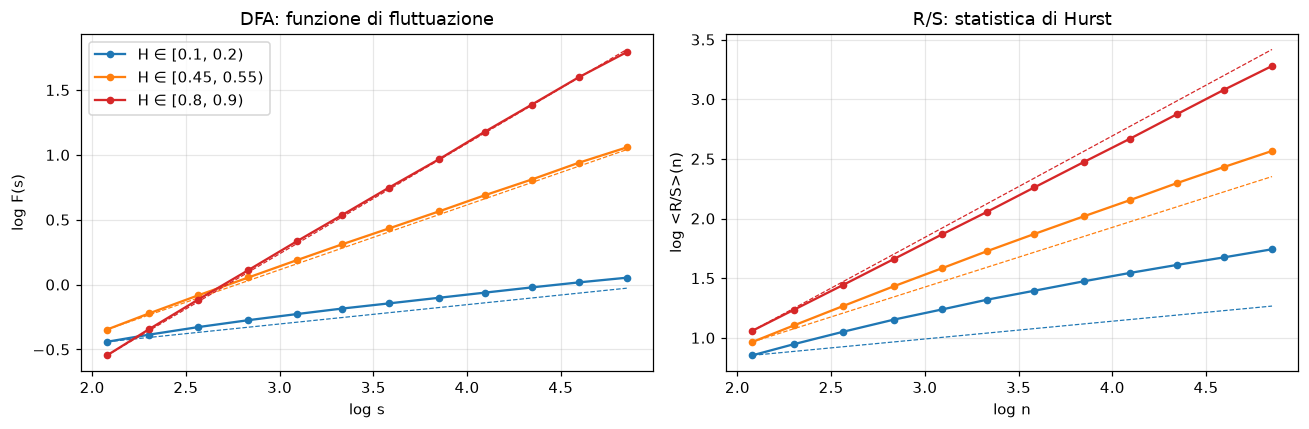

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ls = np.log(scales)
for lo, hi, c in [(0.1, 0.2, "C0"), (0.45, 0.55, "C1"), (0.8, 0.9, "C3")]:
    m = (H["train"] >= lo) & (H["train"] < hi)
    hc = H["train"][m].mean()
    for ax, key in [(axes[0], "logF"), (axes[1], "logRS")]:
        curve = feats["train"][key][m].mean(0)
        ax.plot(ls, curve, "o-", color=c, ms=4, label=f"H ∈ [{lo}, {hi})")
        ax.plot(ls, curve[0] + hc * (ls - ls[0]), "--", color=c, lw=0.8)
axes[0].set(xlabel="log s", ylabel="log F(s)", title="DFA: funzione di fluttuazione")
axes[1].set(xlabel="log n", ylabel="log <R/S>(n)", title="R/S: statistica di Hurst")
axes[0].legend(); plt.tight_layout(); savefig("curve_dfa_rs"); plt.show()

**Ricalibrazione.** Per ogni stimatore $\hat H$ fittiamo sul **solo train** la retta $H = a + b\hat H$
(minimi quadrati). È l'apprendimento più semplice possibile (2 parametri) e corregge il bias sistematico
dovuto a $N$ finito. La retta si applica poi invariata a validation e test.

In [7]:
def calibrate(name, est):
    """est: dict split -> stima grezza. Fitta H = a + b*est sul train, imputando eventuali NaN con
    la mediana del train (contati e riportati)."""
    med = np.nanmedian(est["train"])
    filled = {s: np.where(np.isfinite(v), v, med) for s, v in est.items()}
    b, a = np.polyfit(filled["train"], H["train"], 1)
    n_nan = {s: int((~np.isfinite(v)).sum()) for s, v in est.items() if (~np.isfinite(v)).any()}
    print(f"{name:<28} H = {a:+.3f} {b:+.3f}·Ĥ" + (f"   NaN imputati: {n_nan}" if n_nan else ""))
    return {s: a + b * v for s, v in filled.items()}

dfa = {s: f["dfa"] for s, f in feats.items()}
rs = {s: f["rs"] for s, f in feats.items()}
PRED["1a DFA"] = dfa
PRED["1b R/S"] = rs
PRED["1a-cal DFA ricalibrata"] = calibrate("DFA", dfa)
PRED["1b-cal R/S ricalibrata"] = calibrate("R/S", rs)

DFA                          H = -0.008 +1.001·Ĥ
R/S                          H = -0.285 +1.383·Ĥ


## 5. Approccio 2 — grafi di visibilità senza apprendimento

**Relazione di Lacasa et al. (EPL 86, 30001, 2009).** Per il fBm la distribuzione dei gradi della NVG ha
coda a legge di potenza $P(k)\sim k^{-\gamma}$ con

$$\gamma = 3 - 2H \quad\text{(NVG del fBm)},\qquad \gamma = 5-2H \quad \text{(NVG del fGn, forma riportata in letteratura successiva)}.$$

Quindi $\hat H = (3-\hat\gamma)/2$ senza alcun apprendimento. Lo stesso articolo riporta un fit numerico
$\gamma\approx 3.1-2H$, e lavori successivi propongono correzioni: la relazione è asintotica, per serie lunghe.

**Stima di $\gamma$.** Usiamo lo stimatore di massima verosimiglianza di Clauset, Shalizi e Newman (2009),
con $k_{\min}$ scelto minimizzando la distanza di Kolmogorov–Smirnov e almeno 50 punti in coda (D-21).
È il metodo standard; la regressione lineare sull'istogramma in scala log-log è nota per essere distorta.

Per l'HVG non esiste una relazione analitica $\lambda(H)$ per il fBm (per rumore i.i.d. $\lambda=\ln\frac32$
esattamente): l'esponente $\lambda$ della coda esponenziale entra solo nella versione ricalibrata.

In [8]:
g = {s: f["graph"] for s, f in feats.items()}
col = {name: j for j, name in enumerate(GF)}
gamma_fbm = {s: v[:, col["nvg_fbm_gamma"]] for s, v in g.items()}
gamma_fgn = {s: v[:, col["nvg_fgn_gamma"]] for s, v in g.items()}
lam_fgn = {s: v[:, col["hvg_fgn_lambda"]] for s, v in g.items()}

def fill_nan(est, name):
    """Le stime analitiche non hanno un train: se gamma non è stimabile si usa la media del train
    (cioè la baseline), e lo si conta."""
    n = {s: int((~np.isfinite(v)).sum()) for s, v in est.items()}
    if any(n.values()):
        print(f"{name}: stime non disponibili -> media del train: {n}")
    return {s: np.where(np.isfinite(v), v, H_mean_train) for s, v in est.items()}

PRED["2a NVG(fBm) Lacasa"] = fill_nan({s: u.hurst_from_nvg_gamma(v, "fbm") for s, v in gamma_fbm.items()}, "2a")
PRED["2b NVG(fGn) Lacasa"] = fill_nan({s: u.hurst_from_nvg_gamma(v, "fgn") for s, v in gamma_fgn.items()}, "2b")
PRED["2-cal NVG(fBm) gamma ricalibrato"] = calibrate("NVG(fBm) gamma", gamma_fbm)
PRED["2-cal HVG(fGn) lambda ricalibrato"] = calibrate("HVG(fGn) lambda", lam_fgn)

NVG(fBm) gamma               H = +0.211 +0.079·Ĥ
HVG(fGn) lambda              H = -2.663 +7.418·Ĥ


Come appare la distribuzione dei gradi della NVG su una sola serie della nostra lunghezza?
Mostriamo la funzione di ripartizione complementare (CCDF, come negli appunti par. 6.2: più stabile
dell'istogramma nelle code) per tre valori di $H$, con la retta di pendenza $-(\gamma-1)$ prevista dalla
relazione di Lacasa.

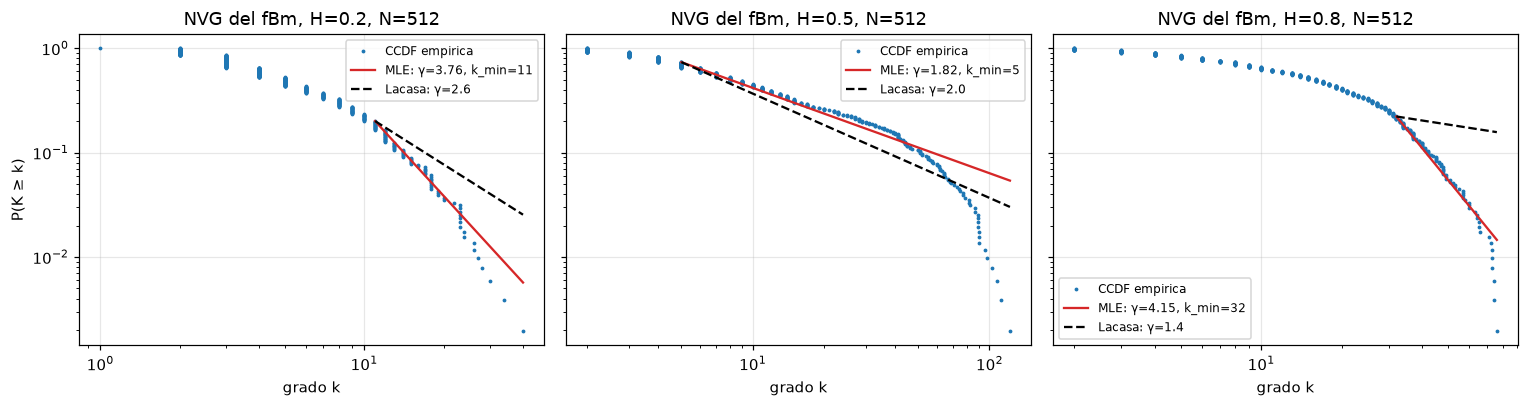

In [9]:
from ts2vg import NaturalVG
rng_demo = np.random.default_rng(SEED + 5)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, Hd in zip(axes, [0.2, 0.5, 0.8]):
    w = u.fbm_from_fgn(u.simulate_fgn(CFG["N"], [Hd], rng_demo))[0]
    gr = NaturalVG(); gr.build(w); k = np.sort(gr.degrees)
    ccdf = 1 - np.arange(len(k)) / len(k)
    ax.loglog(k, ccdf, ".", ms=3, label="CCDF empirica")
    gam, kmin, ks = u.powerlaw_mle(k)
    kk = np.geomspace(kmin, k.max(), 20)
    frac = (k >= kmin).mean()
    ax.loglog(kk, frac * (kk / kmin) ** (1 - gam), "C3-", label=f"MLE: γ={gam:.2f}, k_min={kmin:.0f}")
    gth = 3 - 2 * Hd
    ax.loglog(kk, frac * (kk / kmin) ** (1 - gth), "k--", label=f"Lacasa: γ={gth:.1f}")
    ax.set(title=f"NVG del fBm, H={Hd}, N={CFG['N']}", xlabel="grado k")
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.legend(fontsize=8)
axes[0].set_ylabel("P(K ≥ k)")
plt.tight_layout(); savefig("ccdf_nvg"); plt.show()

**La relazione vale almeno per serie lunghe?** Se l'approccio 2 fallisce alle nostre lunghezze, dobbiamo
distinguere tra "relazione sbagliata / codice sbagliato" ed "effetto di taglia finita". Ripetiamo la stima su
serie molto più lunghe ($N = 16384$), 10 serie per valore di $H$.

gamma mediano               dispersione (IQR)                \
N              512    4096   16384             512    4096   16384   
H vero                                                               
0.20           3.307  3.138  3.233             0.603  0.309  0.210   
0.35           3.428  2.741  2.858             1.179  0.266  0.276   
0.50           2.465  2.435  2.341             1.247  0.398  0.337   
0.65           4.058  2.119  1.809             1.345  1.174  0.183   
0.80           3.513  2.466  1.925             1.661  1.208  1.112   

       H stimato (mediana)                
N                    512    4096   16384  
H vero                                    
0.20                -0.153 -0.069 -0.116  
0.35                -0.214  0.129  0.071  
0.50                 0.268  0.282  0.330  
0.65                -0.529  0.440  0.596  
0.80                -0.256  0.267  0.538

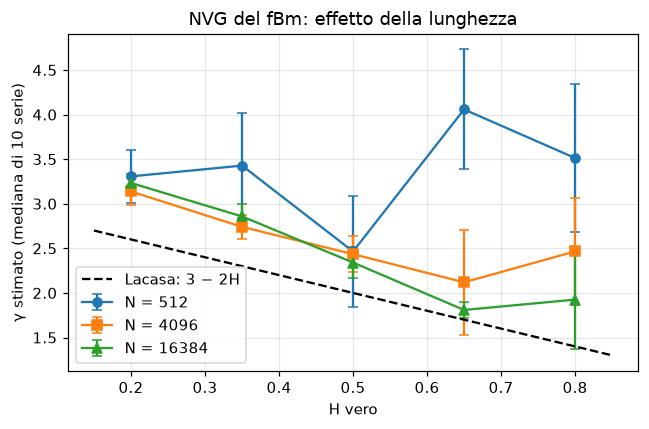

In [10]:
rng_long = np.random.default_rng(SEED + 9)
rows = []
for N_long in [CFG["N"], 4096, 16384]:
    for Hl in [0.2, 0.35, 0.5, 0.65, 0.8]:
        gams = []
        for _ in range(10):
            w = u.fbm_from_fgn(u.simulate_fgn(N_long, [Hl], rng_long))[0]
            gr = NaturalVG(); gr.build(w)
            gams.append(u.powerlaw_mle(gr.degrees)[0])
        gams = np.array(gams)
        rows.append({"N": N_long, "H vero": Hl, "gamma atteso 3-2H": 3 - 2 * Hl,
                     "gamma mediano": np.nanmedian(gams), "dispersione (IQR)": np.subtract(*np.nanpercentile(gams, [75, 25])),
                     "H stimato (mediana)": (3 - np.nanmedian(gams)) / 2})
df_long = pd.DataFrame(rows).round(3)
display(df_long.pivot(index="H vero", columns="N", values=["gamma mediano", "dispersione (IQR)", "H stimato (mediana)"]))

fig, ax = plt.subplots(figsize=(6, 4))
for N_long, mk in zip([CFG["N"], 4096, 16384], ["o", "s", "^"]):
    d = df_long[df_long["N"] == N_long]
    ax.errorbar(d["H vero"], d["gamma mediano"], yerr=d["dispersione (IQR)"] / 2, fmt=mk + "-", capsize=3, label=f"N = {N_long}")
hh = np.linspace(0.15, 0.85, 10)
ax.plot(hh, 3 - 2 * hh, "k--", label="Lacasa: 3 − 2H")
ax.set(xlabel="H vero", ylabel="γ stimato (mediana di 10 serie)", title="NVG del fBm: effetto della lunghezza")
ax.legend(); plt.tight_layout(); savefig("lacasa_vs_N"); plt.show()

## 6. Confronto sul test set

Metriche sul **test** (mai usato per scegliere nulla). Tra parentesi l'intervallo di confidenza bootstrap
al 95% dell'RMSE. La colonna "std previsioni" serve a riconoscere un metodo che predice valori vicini alla
media: la deviazione standard del vero $H$ è ≈ 0.26.

In [11]:
rows = []
for name, p in PRED.items():
    m = u.regression_metrics(H["test"], p["test"])
    lo, hi = u.bootstrap_ci(H["test"], p["test"], "RMSE", n_boot=N_BOOT, seed=SEED)
    rows.append({"metodo": name, "RMSE": m["RMSE"], "IC 95% RMSE": f"[{lo:.3f}, {hi:.3f}]",
                 "MAE": m["MAE"], "bias": m["bias"], "R2": m["R2"], "std previsioni": m["std previsioni"]})
df_res = pd.DataFrame(rows).set_index("metodo")
display(df_res.round(3))
print(f"std di H vero nel test: {H['test'].std():.3f}")

,RMSE,IC 95% RMSE,MAE,bias,R2,std previsioni
metodo,,,,,,
0 baseline (media),0.259,"[0.254, 0.264]",0.223,0.000,-0.000,0.000
1a DFA,0.053,"[0.051, 0.055]",0.041,0.005,0.958,0.252
1b R/S,0.110,"[0.108, 0.113]",0.094,0.066,0.818,0.183
1a-cal DFA ricalibrata,0.053,"[0.051, 0.055]",0.041,-0.002,0.958,0.253
1b-cal R/S ricalibrata,0.054,"[0.052, 0.055]",0.042,-0.002,0.957,0.253
2a NVG(fBm) Lacasa,1.177,"[1.118, 1.250]",0.854,-0.845,-19.630,0.688
2b NVG(fGn) Lacasa,0.491,"[0.479, 0.503]",0.406,0.324,-2.591,0.221
2-cal NVG(fBm) gamma ricalibrato,0.241,"[0.235, 0.247]",0.202,-0.001,0.134,0.108
2-cal HVG(fGn) lambda ricalibrato,0.124,"[0.120, 0.128]",0.100,-0.002,0.770,0.226


std di H vero nel test: 0.259


**Previsto contro vero.** La diagonale è la stima perfetta. I pannelli condividono gli assi, così i metodi
fuori scala restano visibili (le stime grezze non sono vincolate in $[0,1]$: non le tagliamo, per non
nascondere il problema).

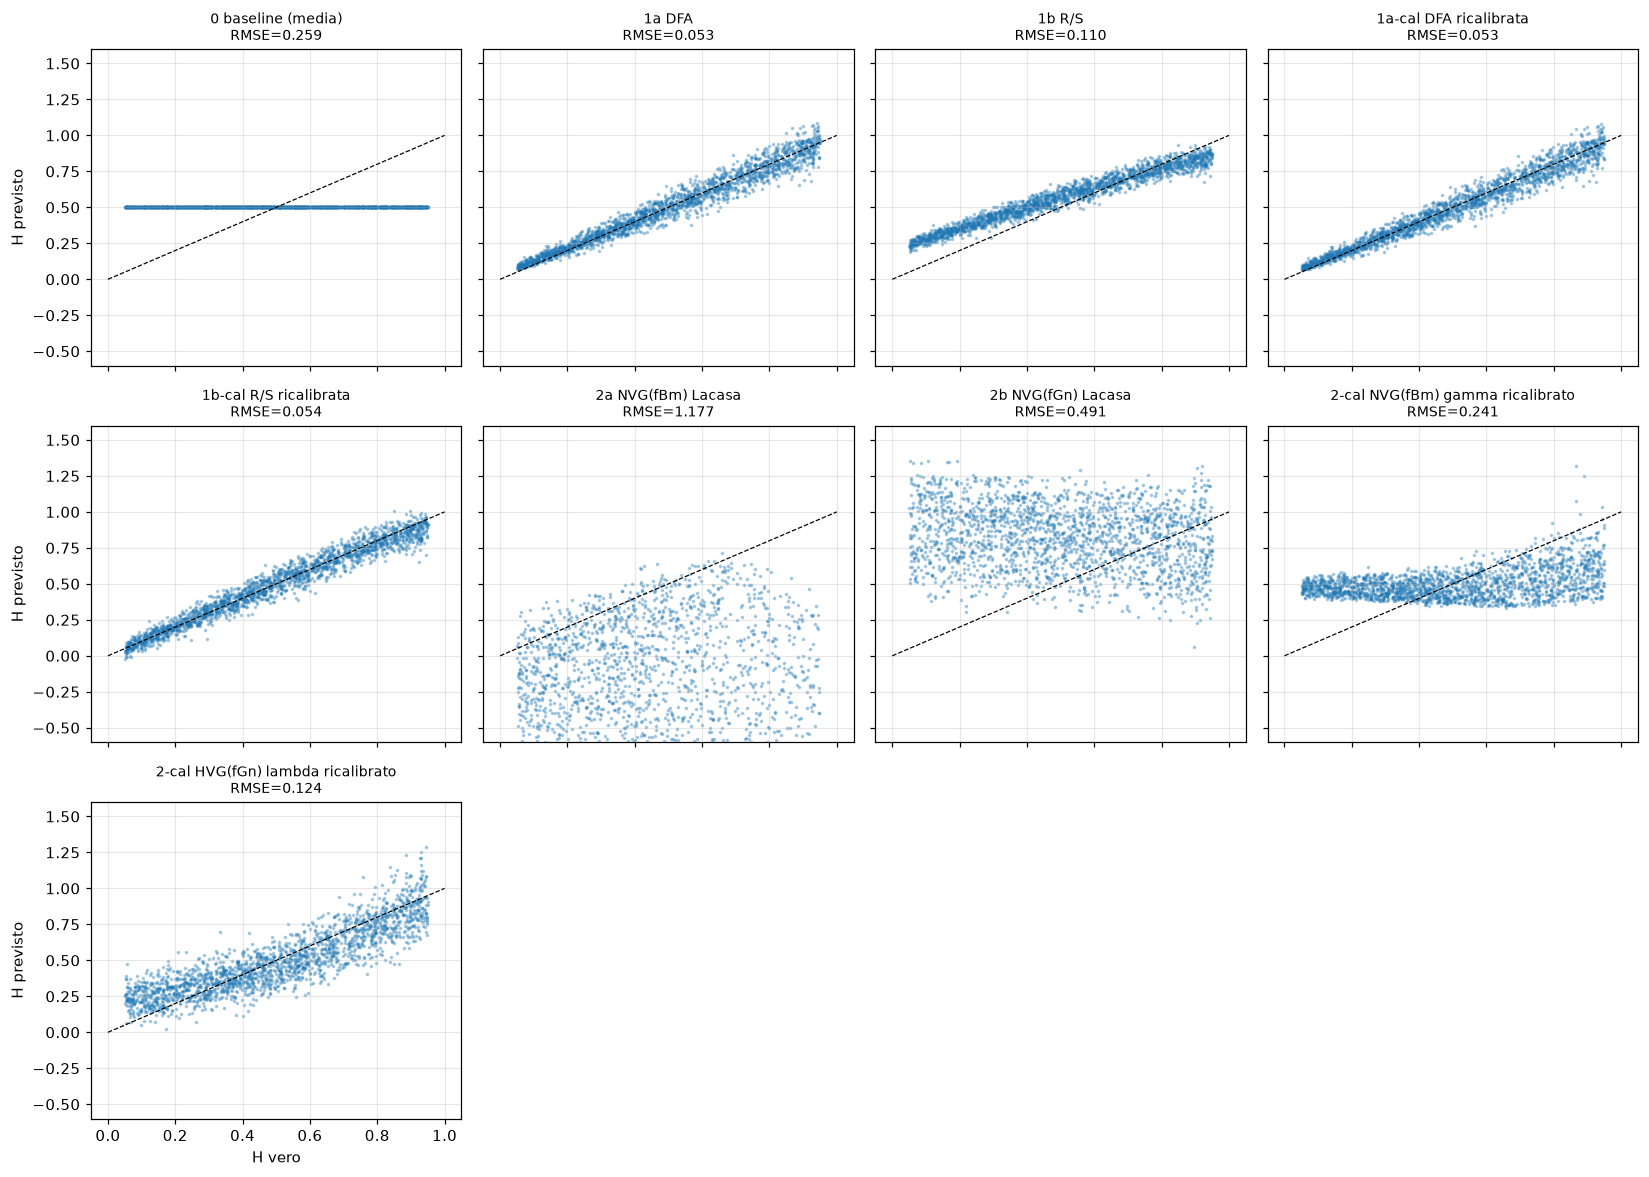

In [12]:
names = list(PRED)
ncol = 4
nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.6 * nrow), sharex=True, sharey=True)
for ax, name in zip(axes.flat, names):
    p = PRED[name]["test"]
    ax.scatter(H["test"], p, s=2, alpha=0.3)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{name}\nRMSE={df_res.loc[name, 'RMSE']:.3f}", fontsize=9)
    ax.set_ylim(-0.6, 1.6)
for ax in axes.flat[len(names):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("H vero")
for ax in axes[:, 0]:
    ax.set_ylabel("H previsto")
plt.tight_layout(); savefig("scatter"); plt.show()

**Distribuzione delle previsioni** (il vero $H$ è uniforme: un istogramma concentrato al centro indica
regressione verso la media) e **errore in funzione del valore vero** (bias e RMSE in 9 classi di $H$).

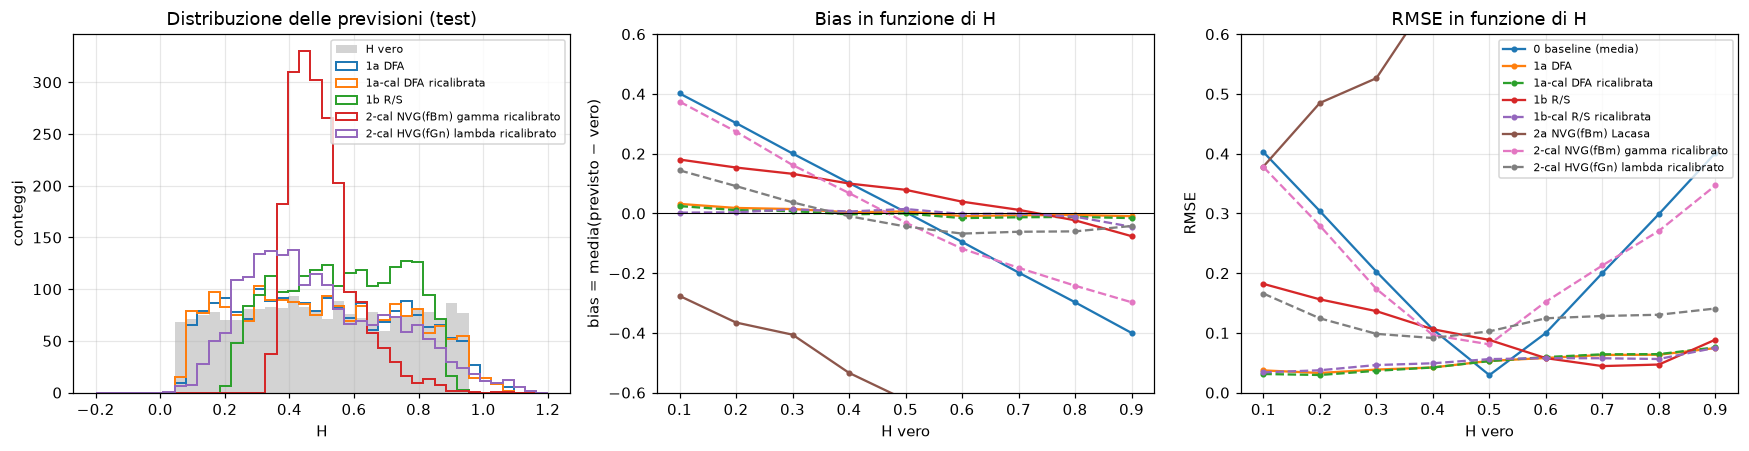

In [13]:
main = ["0 baseline (media)", "1a DFA", "1a-cal DFA ricalibrata", "1b R/S", "1b-cal R/S ricalibrata",
        "2a NVG(fBm) Lacasa", "2-cal NVG(fBm) gamma ricalibrato", "2-cal HVG(fGn) lambda ricalibrato"]
bins = np.linspace(0.05, 0.95, 10)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(H["test"], bins=40, range=(-0.2, 1.2), histtype="stepfilled", color="lightgrey", label="H vero")
for name in ["1a DFA", "1a-cal DFA ricalibrata", "1b R/S", "2-cal NVG(fBm) gamma ricalibrato", "2-cal HVG(fGn) lambda ricalibrato"]:
    axes[0].hist(PRED[name]["test"], bins=40, range=(-0.2, 1.2), histtype="step", lw=1.3, label=name)
axes[0].set(xlabel="H", ylabel="conteggi", title="Distribuzione delle previsioni (test)")
axes[0].legend(fontsize=7)
for name in main:
    be = u.binned_errors(H["test"], PRED[name]["test"], bins)
    ls_ = "--" if "cal" in name else "-"
    axes[1].plot(be["centers"], be["bias"], ls_, marker="o", ms=3, label=name)
    axes[2].plot(be["centers"], be["rmse"], ls_, marker="o", ms=3, label=name)
axes[1].axhline(0, color="k", lw=0.7)
axes[1].set(xlabel="H vero", ylabel="bias = media(previsto − vero)", title="Bias in funzione di H", ylim=(-0.6, 0.6))
axes[2].set(xlabel="H vero", ylabel="RMSE", title="RMSE in funzione di H", ylim=(0, 0.6))
axes[2].legend(fontsize=7, loc="upper right")
plt.tight_layout(); savefig("errore_vs_H"); plt.show()

## 7. Robustezza rispetto alla lunghezza $N$

Applichiamo gli stessi stimatori ai set di solo test con lunghezze diverse (generati nel notebook 01, D-16).
Le rette di ricalibrazione sono quelle fittate alla lunghezza del train: se il bias dipende da $N$,
la ricalibrazione non si trasferisce.

N,128,256,512,1024,2048
metodo,,,,,
1a DFA,0.101,0.072,0.053,0.040,0.034
1a-cal DFA ricalibrata,0.100,0.071,0.053,0.040,0.034
1b R/S,0.155,0.126,0.110,0.093,0.089
1b-cal R/S ricalibrata,0.112,0.075,0.054,0.042,0.041
2-cal HVG(fGn) lambda ricalibrato,0.366,0.196,0.124,0.117,0.126
2a NVG(fBm) Lacasa,0.578,0.881,1.177,0.939,0.753


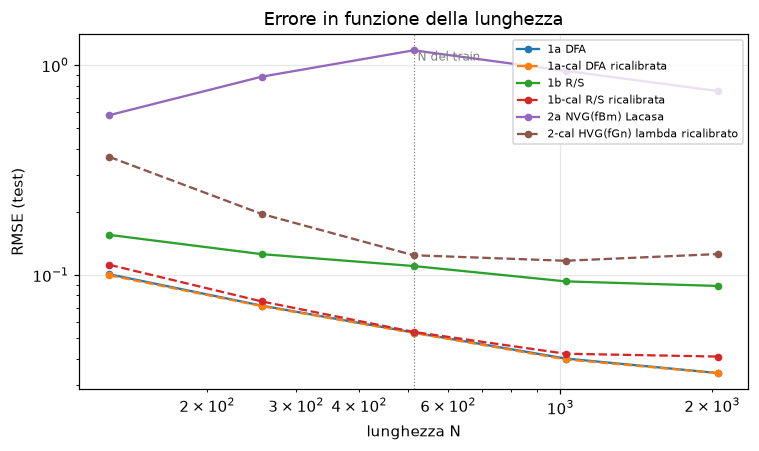

In [14]:
lengths = sorted([CFG["N"]] + list(CFG["robust_lengths"]))
split_of = {L: ("test" if L == CFG["N"] else f"test_N{L}") for L in lengths}
rob = ["1a DFA", "1a-cal DFA ricalibrata", "1b R/S", "1b-cal R/S ricalibrata",
       "2a NVG(fBm) Lacasa", "2-cal HVG(fGn) lambda ricalibrato"]
rows = []
for name in rob:
    for L in lengths:
        s = split_of[L]
        rows.append({"metodo": name, "N": L, "RMSE": u.regression_metrics(H[s], PRED[name][s])["RMSE"]})
df_rob = pd.DataFrame(rows).pivot(index="metodo", columns="N", values="RMSE")
display(df_rob.round(3))
fig, ax = plt.subplots(figsize=(7, 4.2))
for name in rob:
    ax.plot(lengths, df_rob.loc[name, lengths], "--o" if "cal" in name else "-o", ms=4, label=name)
ax.axvline(CFG["N"], color="grey", lw=0.8, ls=":")
ax.text(CFG["N"], ax.get_ylim()[1] * 0.95, " N del train", color="grey", fontsize=8, va="top")
ax.set(xscale="log", yscale="log", xlabel="lunghezza N", ylabel="RMSE (test)", title="Errore in funzione della lunghezza")
ax.legend(fontsize=7); plt.tight_layout(); savefig("rmse_vs_N"); plt.show()

## 8. Salvataggio delle previsioni

Le previsioni di tutti i metodi su tutti gli split vanno in `data/`, per la tabella finale (notebook 06).

In [15]:
out = Path(DATA_DIR) / f"preds02_{MODE}_seed{SEED}.npz"
np.savez_compressed(out, **{f"{name}__{s}": v for name, d in PRED.items() for s, v in d.items()})
df_res.to_csv(Path(DATA_DIR) / f"results02_{MODE}.csv")
print("Salvato", out)

Salvato data\preds02_quick_seed2026.npz


## 9. Riepilogo

In [16]:
best = df_res.drop(index="0 baseline (media)")["RMSE"].idxmin()
print(f"Migliore su test: {best}  (RMSE {df_res.loc[best, 'RMSE']:.3f})")
beats = df_res["RMSE"] < df_res.loc["0 baseline (media)", "RMSE"]
print("Battono la baseline:", list(df_res.index[beats & (df_res.index != "0 baseline (media)")]))
print("Non battono la baseline:", list(df_res.index[~beats]))

Migliore su test: 1a-cal DFA ricalibrata  (RMSE 0.053)
Battono la baseline: ['1a DFA', '1b R/S', '1a-cal DFA ricalibrata', '1b-cal R/S ricalibrata', '2-cal NVG(fBm) gamma ricalibrato', '2-cal HVG(fGn) lambda ricalibrato']
Non battono la baseline: ['0 baseline (media)', '2a NVG(fBm) Lacasa', '2b NVG(fGn) Lacasa']


**Cosa mostra questo notebook** (i numeri esatti sono nelle tabelle sopra; commenti scritti sulla modalità
`quick` e da ricontrollare sulla `full`)

- **La DFA è lo stimatore classico migliore ed è praticamente non distorta**: la retta di ricalibrazione
  fittata sul train è quasi l'identità e non cambia l'RMSE. Il suo errore cresce con $H$ (le serie persistenti
  hanno meno "campioni indipendenti"). È il termine di paragone da battere per le reti.
- **R/S grezzo è distorto** verso $H=0.5$ per $H$ piccolo (bias noto per finestre corte, Anis–Lloyd):
  RMSE circa doppio della DFA, ma correlazione con $H$ altissima. **Ricalibrato, R/S diventa equivalente
  alla DFA**: per la regola del corso ("se le prestazioni sono vicine, scegliere il più semplice") il
  riferimento classico resta la DFA grezza, che non impara nulla.
- **La relazione analitica di Lacasa non funziona alle nostre lunghezze**: 2a e 2b sono *peggiori della
  baseline banale* ($R^2<0$). La CCDF mostra il motivo: su 500–1000 punti la coda della NVG è dominata dal
  taglio di taglia finita (per $H$ grande non c'è un tratto a legge di potenza), e lo stimatore sceglie
  code diverse da serie a serie.
- **Neanche con serie lunghe riproduciamo la relazione.** Con $N$ fino a 16384 la dispersione di $\gamma$
  cala e, per $H\ge0.5$, la mediana si sposta verso $3-2H$; ma per $H<0.5$ $\gamma$ resta ≈ 3–3.2 quasi
  indipendente da $H$, e l'$H$ ricavato resta sistematicamente sotto il vero. Con uno stimatore standard
  (massima verosimiglianza + KS) la relazione $\gamma=3-2H$ non regge; la letteratura successiva riporta
  infatti fit diversi e una forte dipendenza dal metodo di fit dell'esponente. La costruzione dei grafi è
  verificata (notebook 01), quindi il problema è nel passaggio "esponente di legge di potenza → $H$".
- **Il grafo però contiene informazione su $H$**: l'esponente $\lambda$ della coda dell'HVG, ricalibrato con
  una retta, ha $R^2\approx0.77$. Quindi il problema non è la rappresentazione a grafo, ma la riduzione a un
  solo esponente. Questo motiva gli approcci appresi sul grafo (feature multiple nel notebook 03, GNN nel 04).
- **Robustezza:** gli stimatori grezzi migliorano con $N$ (DFA: RMSE da 0.10 a $N=128$ a 0.03 a $N=2048$).
  La ricalibrazione della DFA si trasferisce senza problemi (è quasi l'identità); quella di $\lambda_{\rm HVG}$
  no, perché il legame tra $\lambda$ e $H$ dipende da $N$: un modello calibrato a una lunghezza va usato
  a quella lunghezza.

**Decisioni di questo notebook:** D-20 scale della DFA/R-S; D-21 stimatore dell'esponente (Clauset) e
gestione dei fallimenti; D-22 ricalibrazione lineare come baseline "fisica + 2 parametri";
D-23 nessun taglio delle previsioni in $[0,1]$.